2026-10-31 13:29:30 - INFO - ------- Starting simulation -------
2026-10-31 13:29:30 - INFO - Model: Diff_reaction_problem
2026-10-31 13:29:30 - INFO - Dimension: 1D
2026-10-31 13:29:30 - INFO - Nodes: 11
2026-10-31 13:29:30 - INFO - Elements: 10
2026-10-31 13:29:30 - INFO - Physics: Transport of Chemical Species
2026-10-31 13:29:30 - INFO - ------- Solver configuration -------
2026-10-31 13:29:30 - INFO - Study: Steady state
2026-10-31 13:29:30 - INFO - Type: Nonlinear
2026-10-31 13:29:30 - INFO - Method: Direct
2026-10-31 13:29:30 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-10-31 13:29:30 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-10-31 13:29:30 - INFO - Relative tolerance: 1.0e-10, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-10-31 13:29:30 - INFO - -----------------------------------------------------------
2026-10-31 13:29:30 - INFO - |  Iter  |  ||R|| scaled   |  ||R||/||R0||   | Alpha (Step)
2026-10-31 13:29:30 - I

Text(0, 0.5, 'Concentration [mol/m3]')

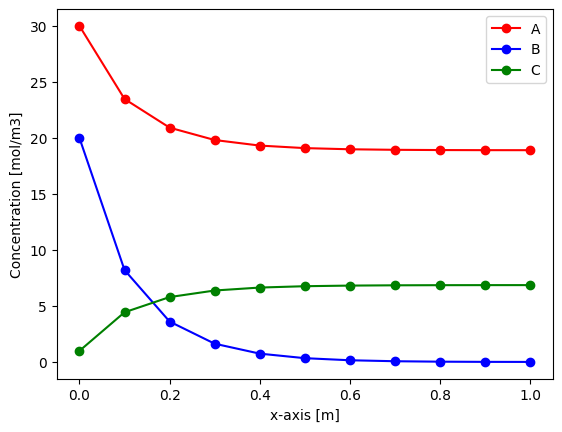

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from Source.Pre_processing.Mesh import Mesh
from Source.core import Model
from Source.Material import material
from Source.Physics.MassTransfer import mt

from Source.enums import ElementType, ShapeFunctionType, StudyType, ProblemType, SolverType, DirectSolvers


# Defining problem dimension: 1D
PD = 1 

# Create mesh from linear element

L = 1  # Length size of the domain [m]
NoE = 10  # Number of Elements
MeshType = ElementType.line  # Type of element
shapeFunction = ShapeFunctionType.linear  # Shape function for spatial discretization

Mesh1 = Mesh()
Mesh1.Generate_Mesh(PD, L, NoE, MeshType)
Mesh1.setElementShapeFunction(shapeFunction)

Mesh1.defineBoundary('inlet', 0)
Mesh1.defineBoundary('outlet', NoE) # Hardcoded

# Defining material properties
Mat1 = material('Media', k = 0.2, miu=1, rho=1, Cp= 1)

Model1 = Model(name='Diff_reaction_problem', mtype=None, dim=PD, mesh=Mesh1, mat=Mat1, psc=mt)

Model1.physics.setChemSpecies('A', 'Component A')
Model1.physics.setChemSpecies('B', 'Component B')
Model1.physics.setChemSpecies('C', 'Component C')

Model1.physics.setDiffusivity('A', 1)
Model1.physics.setDiffusivity('B', 0.5)
Model1.physics.setDiffusivity('C', 2)

# Neglecting convection term
Model1.physics.Convection = True
Model1.physics.Stab = None

# Add Boundary condition
Model1.physics.addBC_Concentration(0, 'A', 30)
Model1.physics.addBC_Concentration(0, 'B', 20)
Model1.physics.addBC_Concentration(0, 'C', 1)

Model1.physics.addBC_Outflow(Mesh1.boundaries['outlet'], 'A')
Model1.physics.addBC_Outflow(Mesh1.boundaries['outlet'], 'B')
Model1.physics.addBC_Outflow(Mesh1.boundaries['outlet'], 'C')

# Add reaction
stoich = {'A': -1, 'B': -1, 'C': 1}
order = {'A': 1, 'B': 1, 'C': 0}
k0 = 10
E_R = 500
T = 300
Model1.physics.addReaction(stoich, k0, E_R, T, order)

# Initialize field
Model1.physics.initField('A', 30)
Model1.physics.initField('B', 20)
Model1.physics.initField('C', 1)

solverOptions = {'Study': StudyType.steady_state, 'Type': ProblemType.nonlinear, 'Method': SolverType.direct, 'Solver':DirectSolvers.PARDISO}

Model1.solverConfiguration(**solverOptions)

# Solving PDE
Model1.solve()

plt.plot(Model1.mesh.getXCoor(), Model1.sol['A'], '-or')
plt.plot(Model1.mesh.getXCoor(), Model1.sol['B'], '-ob')
plt.plot(Model1.mesh.getXCoor(), Model1.sol['C'], '-og')
plt.legend(['A', 'B', 'C'])

plt.xlabel("x-axis [m]")
plt.ylabel("Concentration [mol/m3]")